# Supplementary Figure S12b. Number of snRNA-seq cell types per AD colocalized locus

For each deduplicated AD colocalization event, the number of distinct snRNA-seq cell types (Mic, Exc, Inh, Ast, Oli, OPC) whose *cis*-eGene (top bar) or *trans*-eGene / *trans*-eProgram / *trans* global program (bottom bar) colocalizes at that locus. Bars are stacked by the number of cell types (6 to 0, darker = more cell types); 0 means the locus is supported only by bulk-tissue contexts (DLPFC, AC, PCC). Counts only.

This panel in the V1 figure was drawn from the updated 237-CoS table (118 events: 87 *cis*, 115 *trans* loci), whereas panels a, c and d use the older 228-CoS table (112 events: 65 *cis*, 111 *trans* loci). The values here reproduce the V1 panel; the author's injected "fake" signal row is not included (this code version did not inject it).

Input: `data/Figure_S12b_n_celltypes_per_locus.rds`.

In [1]:
suppressPackageStartupMessages(library(ggplot2))
d <- readRDS("data/Figure_S12b_n_celltypes_per_locus.rds")
d

category,n_celltypes,n_loci,total,data_version
<fct>,<int>,<int>,<int>,<chr>
cis-eQTL,6,2,87,237 CoS -> 118 signals
cis-eQTL,5,5,87,237 CoS -> 118 signals
cis-eQTL,4,3,87,237 CoS -> 118 signals
cis-eQTL,3,6,87,237 CoS -> 118 signals
cis-eQTL,2,14,87,237 CoS -> 118 signals
cis-eQTL,1,39,87,237 CoS -> 118 signals
cis-eQTL,0,18,87,237 CoS -> 118 signals
trans-eQTL,6,15,115,237 CoS -> 118 signals
trans-eQTL,5,22,115,237 CoS -> 118 signals


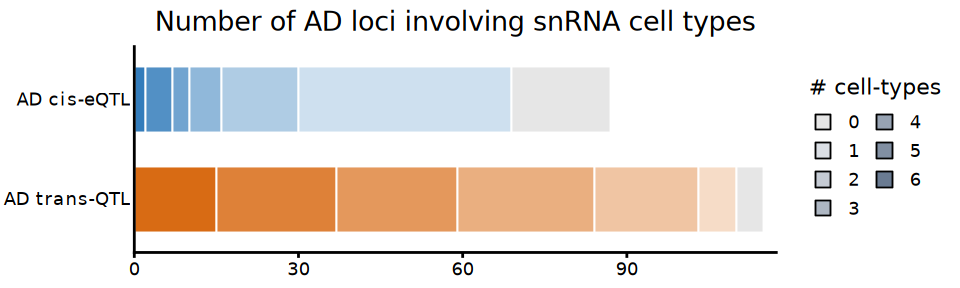

In [2]:
cat_colors <- c("cis-eQTL" = "#2171B5", "trans-eQTL" = "#D55E00")
y_labels <- c(expression(AD ~ italic(cis) * "-eQTL"), expression(AD ~ italic(trans) * "-QTL"))
blend_with_white <- function(hex, w) {
  rgb <- grDevices::col2rgb(hex) / 255
  out <- rgb * (1 - w) + w
  grDevices::rgb(out[1], out[2], out[3])
}
white_weights <- c("1" = 0.78, "2" = 0.64, "3" = 0.50, "4" = 0.36, "5" = 0.22, "6" = 0.08)
d <- d[order(d$category, -d$n_celltypes), ]
d$xmax <- ave(d$n_loci, d$category, FUN = cumsum)
d$xmin <- d$xmax - d$n_loci
d$y <- as.numeric(factor(d$category, levels = rev(levels(d$category))))
d$fill <- mapply(function(cat, n) if (n == 0) "#E6E6E6" else blend_with_white(cat_colors[[cat]], white_weights[[as.character(n)]]),
                 as.character(d$category), d$n_celltypes)
legend_df <- data.frame(n_celltypes = factor(0:6),
                        fill = c("#E6E6E6", sapply(1:6, function(n) blend_with_white("#5D6F88", white_weights[[as.character(n)]]))))
p <- ggplot(d[d$n_loci > 0, ]) +
  geom_rect(aes(xmin = xmin, xmax = xmax, ymin = y - 0.33, ymax = y + 0.33), fill = d$fill[d$n_loci > 0],
            color = "white", linewidth = 0.4) +
  geom_point(data = legend_df, aes(x = 0, y = 1, fill = n_celltypes), shape = 22, size = 0, alpha = 0) +
  scale_fill_manual(values = setNames(legend_df$fill, legend_df$n_celltypes), name = "# cell-types") +
  guides(fill = guide_legend(ncol = 2, override.aes = list(size = 4.5, alpha = 1))) +
  scale_y_continuous(breaks = seq_along(levels(d$category)), labels = rev(y_labels), expand = expansion(add = 0.2)) +
  scale_x_continuous(expand = expansion(mult = c(0, 0.02))) +
  labs(x = NULL, y = NULL, title = "Number of AD loci involving snRNA cell types") +
  theme_classic(base_size = 13) +
  theme(plot.title = element_text(hjust = 0.5), axis.ticks.y = element_blank())

options(repr.plot.width = 8, repr.plot.height = 2.4)
p